In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

##### Answers are written in the code in print statement

#### Question 1: Comparative Edge Detection on Natural Images
Download any outdoor natural image (trees, buildings, roads). Apply Sobel, Laplacian, and Canny edge detection. Compare the outputs and write a short analysis explaining which operator captures the most meaningful edges and why.

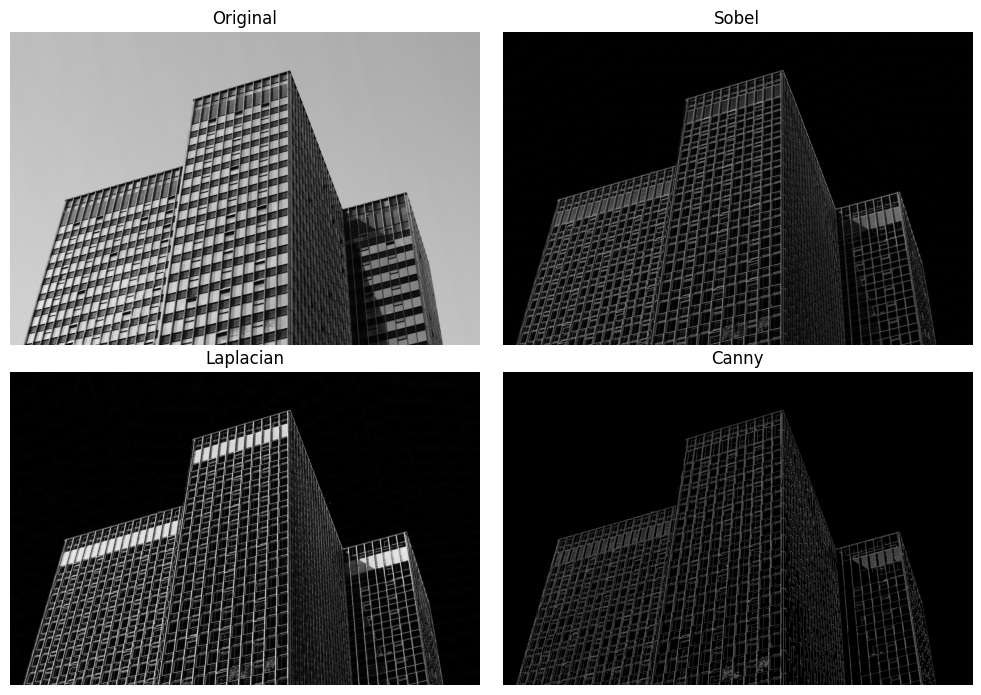



Observation :
Canny captures meaningful edges because it reduces noise, removes weak edges, and connects strong edges.


In [14]:
# Loading grayscale image
img = cv2.imread("Images/Outdoor image.jpg", 0)

# Applying Sobel operator
sx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.addWeighted(cv2.convertScaleAbs(sx), 0.5,
                        cv2.convertScaleAbs(sy), 0.5, 0)

# Applying Laplacian and Canny
laplacian = cv2.convertScaleAbs(cv2.Laplacian(img, cv2.CV_64F, ksize=3))
canny = cv2.Canny(img, 100, 200)

# Displaying results
plt.figure(figsize=(10, 7))
for i, (image, title) in enumerate(zip(
    [img, sobel, laplacian, canny],
    ["Original", "Sobel", "Laplacian", "Canny"]
)):
    plt.subplot(2, 2, i+1)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n\nObservation :")
print("Canny captures meaningful edges because it reduces noise, removes weak edges, and connects strong edges.")

#### Question 2 :Noise Sensitivity Experiment Take a clean grayscale image and intentionally add Gaussian noise and salt-and-pepper noise. Apply Sobel and Laplacian on both noisy versions and evaluate:
    - Which operator is more affected by noise?
    - How does edge clarity change?
    - What preprocessing step improves the results?


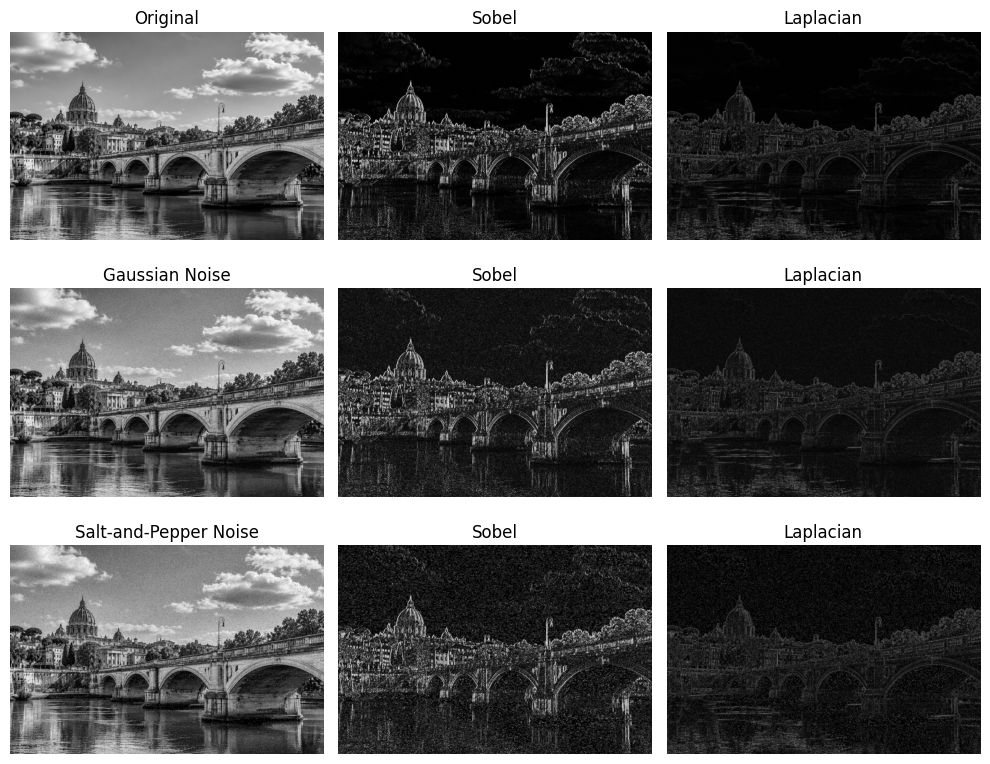



Answers :
Answer 1 : Laplacian is more sensitive to noise because even small intensity changes affect it.
Answer 2 : Noise creates extra edges, making the image less clear.
Answer 3 : Gaussian blur smooths the image and reduces noise before edge detection.


In [15]:
# Loading clean grayscale image
img = cv2.imread("Images/grayscale.png", 0)

# Adding Gaussian and salt-and-pepper noise
gaussian = np.clip(img + np.random.normal(0, 20, img.shape),
                   0, 255).astype(np.uint8)

sp = img.copy()
noise = np.random.rand(*img.shape)
sp[noise < 0.02] = 0
sp[noise > 0.98] = 255

# Applying Sobel and Laplacian
plt.figure(figsize=(10, 8))
for i, (image, title) in enumerate(zip(
    [img, gaussian, sp],
    ["Original", "Gaussian Noise", "Salt-and-Pepper Noise"]
)):
    blurred = cv2.GaussianBlur(image, (5, 5), 1)
    sx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sobel = cv2.convertScaleAbs(sx)
    laplacian = cv2.convertScaleAbs(cv2.Laplacian(blurred, cv2.CV_64F))

    # Displaying results
    for j, (result, name) in enumerate(zip(
        [image, sobel, laplacian], [title, "Sobel", "Laplacian"]
    )):
        plt.subplot(3, 3, i*3+j+1)
        plt.imshow(result, cmap="gray")
        plt.title(name)
        plt.axis("off")

plt.tight_layout()
plt.show()

print("\n\nAnswers :")
print("Answer 1 : Laplacian is more sensitive to noise because even small intensity changes affect it.")
print("Answer 2 : Noise creates extra edges, making the image less clear.")
print("Answer 3 : Gaussian blur smooths the image and reduces noise before edge detection.")

#### Question 3 : Compression Ratio Comparison (RLE vs Huffman) Load a grayscale image with large smooth regions (e.g., document scan or sky image).Compress it using Run-Length Encoding and Huffman Coding separately.Calculate and compare:
    - Bit-length before compression
    - Bit-length after compression
    - Percentage reduction

In [16]:
import heapq

# Load grayscale image
img = cv2.imread("Images/street.jpg", 0)
flat = img.flatten()

# Apply Run-Length Encoding
rle = []
count = 1
for i in range(1, len(flat)):
    if flat[i] == flat[i-1]:
        count += 1
    else:
        rle.append((flat[i-1], count))
        count = 1
rle.append((flat[-1], count))

# Calculate RLE bit length
rle_bits = sum(8 + count.bit_length() for _, count in rle)

# Calculate pixel frequencies
freq = {}
for pixel in flat:
    freq[pixel] = freq.get(pixel, 0) + 1

# Build Huffman tree
heap = [[weight, [symbol, ""]] for symbol, weight in freq.items()]
heapq.heapify(heap)

if len(heap) == 1:
    codes = {heap[0][1][0]: "0"}
else:
    while len(heap) > 1:
        low1 = heapq.heappop(heap)
        low2 = heapq.heappop(heap)
        for pair in low1[1:]:
            pair[1] = "0" + pair[1]
        for pair in low2[1:]:
            pair[1] = "1" + pair[1]
        heapq.heappush(heap, [low1[0]+low2[0]] + low1[1:] + low2[1:])
    codes = dict(heap[0][1:])

# Compare compression sizes
original_bits = len(flat) * 8
huffman_bits = sum(freq[p] * len(codes[p]) for p in freq)

print("Original bits:", original_bits)
print("RLE bits:", rle_bits)
print("RLE reduction (%):", (original_bits-rle_bits)/original_bits*100)
print("Huffman bits:", huffman_bits)
print("Huffman reduction (%):", (original_bits-huffman_bits)/original_bits*100)

print("\n\nAnswers :")
print("Answer 1 : Bit-length before compression:", original_bits)
print("Answer 2 : Bit-length after compression - RLE:", rle_bits, "Huffman:", huffman_bits)
print("Answer 3 : Percentage reduction - RLE: 11.09%, Huffman: 7.00%")
print("RLE achieved a higher compression reduction (11.09%) than Huffman coding (7.00%) for this image.")

Original bits: 192000000
RLE bits: 170700769
RLE reduction (%): 11.093349479166667
Huffman bits: 178555375
Huffman reduction (%): 7.002408854166667


Answers :
Answer 1 : Bit-length before compression: 192000000
Answer 2 : Bit-length after compression - RLE: 170700769 Huffman: 178555375
Answer 3 : Percentage reduction - RLE: 11.09%, Huffman: 7.00%
RLE achieved a higher compression reduction (11.09%) than Huffman coding (7.00%) for this image.


#### Question 4 : JPEG Block Artifact Analysis. Implement an 8×8 block-based JPEG-style compression (DCT + quantisation). Compress the same image using low, medium, and high quantisation levels. Analyse:
    - Where block artifacts appear
    - Why some textures lose detail
    - How PSNR and SSIM change at each level


Scale: 0.5 MSE: 8.302504239814317 PSNR: 38.93871254817603 SSIM: 0.9909305790235202
Scale: 1 MSE: 32.66096019132705 PSNR: 32.99051412565696 SSIM: 0.9647842352328165
Scale: 2 MSE: 74.75870242689577 PSNR: 29.394186060654704 SSIM: 0.9186342523242829


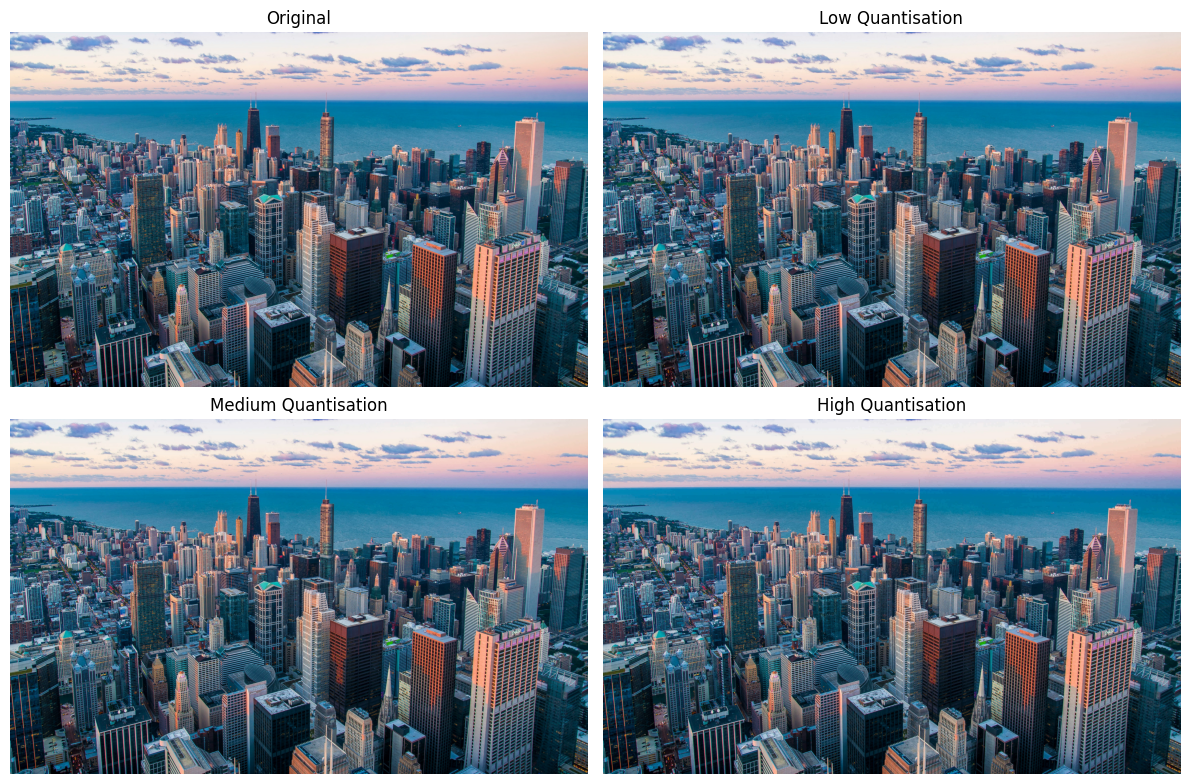



Answers :
Answer 1 : Block artifacts can appear as visible squares between 8x8 pixel blocks.
Answer 2 : Fine details and textures are lost because compression removes image information.
Answer 3 : Higher quantisation usually increases MSE and lowers PSNR and SSIM.


In [17]:
from skimage.metrics import structural_similarity as ssim

# Load image and convert to YCrCb
img = cv2.imread("Images/city.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
Y, Cr, Cb = cv2.split(ycc)

# JPEG quantisation matrix
Q = np.array([
    [16,11,10,16,24,40,51,61],
    [12,12,14,19,26,58,60,55],
    [14,13,16,24,40,57,69,56],
    [14,17,22,29,51,87,80,62],
    [18,22,37,56,68,109,103,77],
    [24,35,55,64,81,104,113,92],
    [49,64,78,87,103,121,120,101],
    [72,92,95,98,112,100,103,99]
])

# Crop dimensions to multiples of 8
h, w = Y.shape
h, w = h//8*8, w//8*8
img, Y, Cr, Cb = img[:h,:w], Y[:h,:w], Cr[:h,:w], Cb[:h,:w]

# Apply DCT and quantisation at three levels
results = []
for scale in [0.5, 1, 2]:
    compressed = np.zeros_like(Y, dtype=np.float32)
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            block = np.float32(Y[i:i+8, j:j+8])
            dct = cv2.dct(block)
            compressed[i:i+8, j:j+8] = cv2.idct(
                np.round(dct/(Q*scale))*(Q*scale)
            )

    # Reconstruct image
    ycc2 = cv2.merge([np.clip(compressed, 0, 255).astype(np.uint8), Cr, Cb])
    output = cv2.cvtColor(ycc2, cv2.COLOR_YCrCb2RGB)
    results.append(output)

    # Calculate MSE, PSNR and SSIM
    mse = np.mean((img.astype(float)-output.astype(float))**2)
    psnr = cv2.PSNR(img, output)
    score = ssim(img, output, channel_axis=2, data_range=255)
    print("Scale:", scale, "MSE:", mse, "PSNR:", psnr, "SSIM:", score)

# Display results
plt.figure(figsize=(12, 8))
for i, (image, title) in enumerate(zip(
    [img] + results,
    ["Original", "Low Quantisation", "Medium Quantisation", "High Quantisation"]
)):
    plt.subplot(2, 2, i+1)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n\nAnswers :")
print("Answer 1 : Block artifacts can appear as visible squares between 8x8 pixel blocks.")
print("Answer 2 : Fine details and textures are lost because compression removes image information.")
print("Answer 3 : Higher quantisation usually increases MSE and lowers PSNR and SSIM.")

#### Question 5 : Texture-Based Segmentation using GLCM Features
Load a synthetic or natural image that contains multiple textures (wood, fabric, leaves, tiles).Extract GLCM features (contrast, energy, homogeneity) for each pixel neighbourhood.Segment the image into k = 3 clusters using these features. Write observations on how feature choice influences segmentation quality.

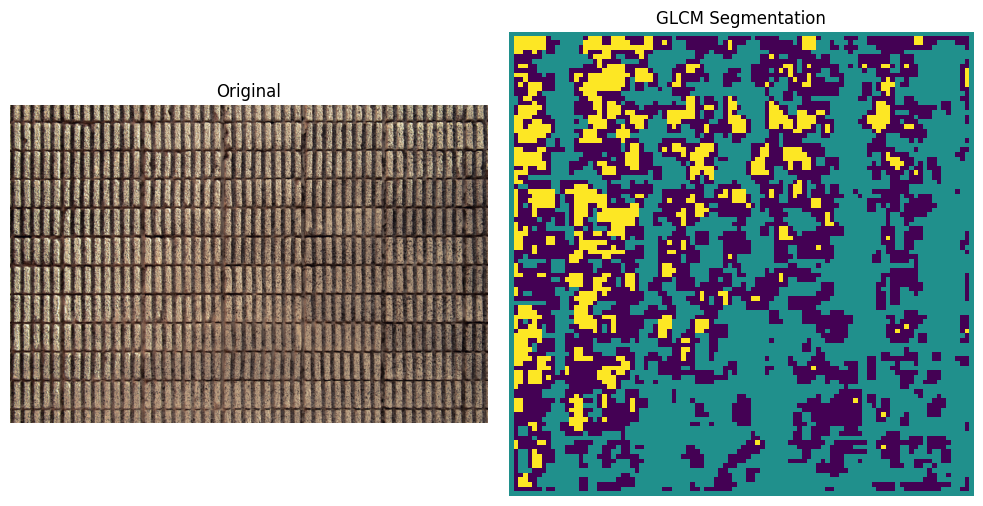



Observation :
GLCM features help distinguish textures by looking at their contrast, smoothness and similarity.


In [18]:
from skimage.feature import graycomatrix, graycoprops

# Load and convert image to grayscale
img = cv2.imread("Images/texture.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (100, 100))
gray = (gray // 32).astype(np.uint8)

# Extract local GLCM features
features = np.zeros((100, 100, 3), dtype=np.float32)
for i in range(1, 99):
    for j in range(1, 99):
        block = gray[i-1:i+2, j-1:j+2]
        glcm = graycomatrix(block, [1], [0], levels=8,
                            symmetric=True, normed=True)
        features[i, j] = [
            graycoprops(glcm, "contrast")[0, 0],
            graycoprops(glcm, "energy")[0, 0],
            graycoprops(glcm, "homogeneity")[0, 0]
        ]

# Apply K-means segmentation
pixels = features.reshape((-1, 3))
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
_, labels, _ = cv2.kmeans(pixels, 3, None, criteria, 10,
                          cv2.KMEANS_PP_CENTERS)
segmented = labels.reshape(gray.shape)

# Display results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img[:, :, ::-1])
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap="viridis")
plt.title("GLCM Segmentation")
plt.axis("off")
plt.tight_layout()
plt.show()

print("\n\nObservation :")
print("GLCM features help distinguish textures by looking at their contrast, smoothness and similarity.")

#### Question 6: Multi-Feature Segmentation for Disease Detection
Load a plant or skin lesion image.Construct a feature vector combining:
Intensity
Gradient magnitude (Sobel)
Local texture variance Segment the image using K-means or Mean Shift.Evaluate:
Which feature contributed most to separating diseased vs healthy regions
Any misclassifications and why they occurred


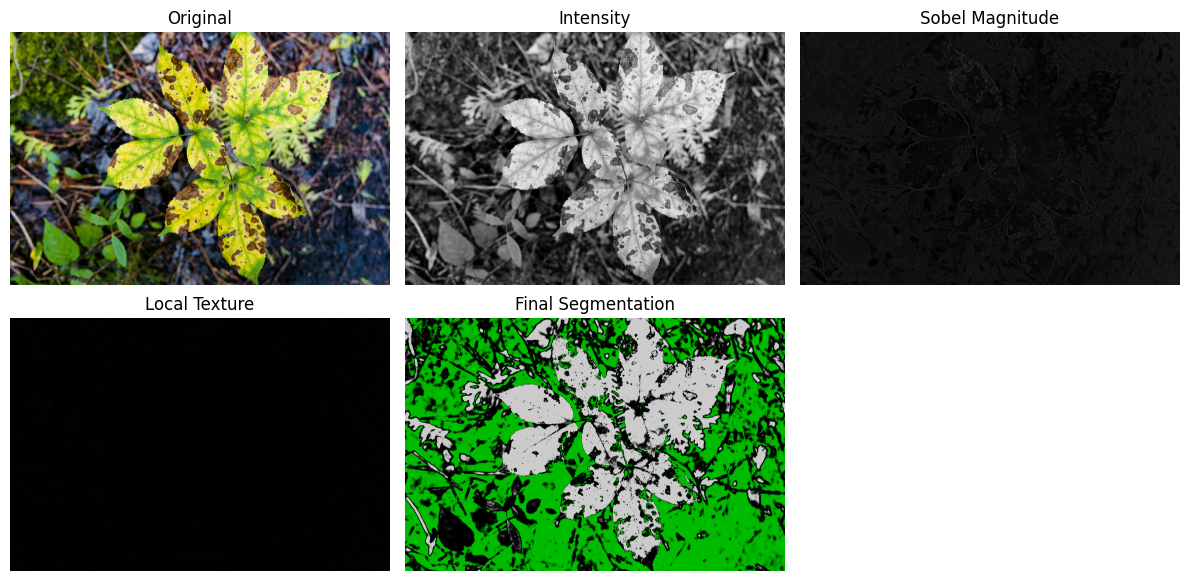



Answers :
Answer 1 : Intensity and texture help identify differences between healthy and diseased areas.
Answer 2 : Some areas may be classified incorrectly if they look similar.


In [19]:
# Load image and convert to grayscale
img = cv2.imread("Images/plant.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Calculate Sobel gradient magnitude
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.normalize(np.sqrt(sx**2 + sy**2), None, 0, 255,
                      cv2.NORM_MINMAX)

# Calculate local texture
kernel = np.ones((3, 3), np.float32)/9
blur = cv2.filter2D(gray, -1, kernel)
texture = cv2.normalize((gray.astype(float)-blur)**2, None,
                        0, 255, cv2.NORM_MINMAX)

# Combine three features
features = np.stack([gray, sobel, texture], axis=2).astype(np.uint8)
h, w = gray.shape
pixels = features.reshape((-1, 3)).astype(np.float32)

# Apply K-means segmentation
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1.0)
_, labels, _ = cv2.kmeans(pixels, 3, None, criteria, 10,
                          cv2.KMEANS_PP_CENTERS)
segmented = labels.reshape((h, w))

# Display results
plt.figure(figsize=(12, 6))
for i, (image, title, cmap) in enumerate([
    (rgb, "Original", None),
    (gray, "Intensity", "gray"),
    (sobel, "Sobel Magnitude", "gray"),
    (texture, "Local Texture", "gray"),
    (segmented, "Final Segmentation", "nipy_spectral")
]):
    plt.subplot(2, 3, i+1)
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n\nAnswers :")
print("Answer 1 : Intensity and texture help identify differences between healthy and diseased areas.")
print("Answer 2 : Some areas may be classified incorrectly if they look similar.")